# 33 · OpenLayers: direct GeoZarr and band expressions

**Time:** 40 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** inspect actual browser GeoZarr rendering; compare band order and display transforms.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=33_eopf_openlayers.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


**Reproducibility record.** Project: Earth in the Browser; author: course contributors;
email/organization: not supplied. Created/updated: 2026-11-21. Input: `data/eopf/`;
outputs: the figures and objects below (exports are named explicitly). Python, NumPy and
Matplotlib; SQLite where used. Initial EOPF teaching release. The acquisition is a
convenience example, not a representative sample. Missing values remain missing.

![EOPF workflow from discovery to direct maps, quality-aware analysis and server processing](assets/eopf-workflow.svg)
## 1. Open the direct browser laboratory

[Open the two-map studio](https://jltobias.github.io/JupyterLite-zarr-sql-views/eopf/).
It uses actual **OpenLayers 10.11.0** and **EOxElements 2.10.0**, adapting the
[official OpenLayers examples](https://explorer.eopf.copernicus.eu/software-services/ol/).
GeoZarr support is evolving. The default reads the checked-in small window from the
same site. Choose **Live EOPF full scene** to request external source chunks; choose
the bundled window again if service access or CORS fails.

The Python cells inspect and reproduce the configuration; the linked page runs JavaScript.
This is not a Python OpenLayers binding. The static figures remain readable in the Book.

In [2]:
from eopf import load_eopf, map_layers, SITE, rgb
d=load_eopf()
layers=map_layers(SITE+'/data/eopf/classroom.zarr/')
print(json.dumps(layers,indent=2))
display(HTML(f'<a href="{SITE}/eopf/" target="_blank" rel="noopener">Open interactive OpenLayers and EOxElements maps</a>'))

[
  {
    "type": "WebGLTile",
    "properties": {
      "id": "sentinel",
      "title": "Sentinel-2 / 120 m overview"
    },
    "source": {
      "type": "GeoZarr",
      "url": "https://jltobias.github.io/JupyterLite-zarr-sql-views/data/eopf/classroom.zarr/",
      "bands": [
        "b04",
        "b03",
        "b02"
      ]
    },
    "style": {
      "gamma": 1.5,
      "color": [
        "color",
        [
          "interpolate",
          [
            "linear"
          ],
          [
            "band",
            1
          ],
          0,
          0,
          0.4,
          255
        ],
        [
          "interpolate",
          [
            "linear"
          ],
          [
            "band",
            2
          ],
          0,
          0,
          0.4,
          255
        ],
        [
          "interpolate",
          [
            "linear"
          ],
          [
            "band",
            3
          ],
          0,
          0,
          0.4

## 2. Observe the network and change the view

1. Open browser developer tools → Network and filter for `zarr.json`, then `/c/`.
2. Reload the bundled window. Metadata is followed by array chunks.
3. Switch true color to false color; B08 now supplies the red display channel.
4. Switch to NDVI; compare with notebook 32. The map has **no SCL mask**.
5. Use keyboard focus and zoom controls. Reset extents after panning.

In OpenLayers, `band` expressions use **one-based** loaded-band indices. For NDVI,
this demo loads `[b08, b04]`, so band 1 is NIR and band 2 is red. It guards invalid
denominators and negative reflectances. Gamma and RGB stretching change appearance,
not the stored numbers. Map pixels are reprojected for display.

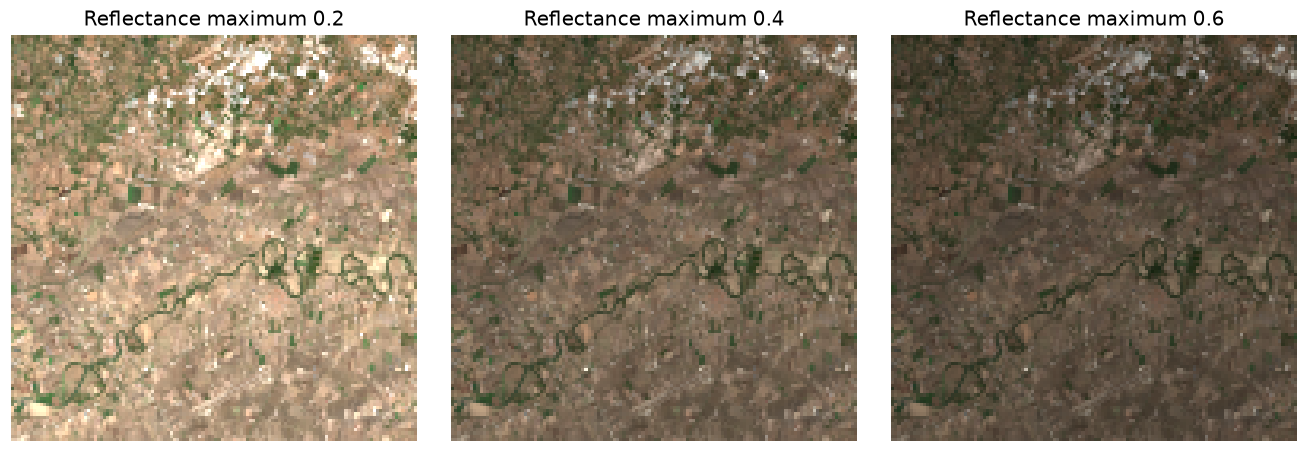

Unchanged red reflectance range: 0.014799997210502625 0.42399999499320984


In [3]:
# Reproduce the RGB stretch with numerical data, not screen colors.
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for ax,maximum in zip(axes,[0.2,0.4,0.6]):
    ax.imshow(rgb(d,maximum=maximum));ax.set_title(f'Reflectance maximum {maximum}');ax.axis('off')
plt.show()
print('Unchanged red reflectance range:',float(d['b04'].min()),float(d['b04'].max()))

## 3. Compare approaches

| Route | Where pixels are processed | What is delivered |
|---|---|---|
| OpenLayers GeoZarr | Browser JavaScript/WebGL | Metadata and numeric chunks |
| EOxElements GeoZarr | Browser, using OpenLayers | Same arrays plus declarative controls |
| TiTiler | External server | Rendered image tiles |
| Python lesson | Browser Pyodide or native Python | Bundled numeric arrays and plots |

Do not count downloaded array bytes as all network traffic: runtimes, scripts and
metadata also have costs. The source's multiscale hierarchy reduces detailed reads
when zoomed out, while the classroom store contains only one resolution.

## Try it yourself

Explain one visible difference caused by band order, one by display stretch, and one by a quality mask.

## Check your reasoning

Band order changes channel meaning; stretch changes display brightness; masking changes which observations contribute. These operations must not be conflated.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [EOPF Sentinel Zarr Explorer](https://explorer.eopf.copernicus.eu/), funded by ESA through the Copernicus Space Component programme; EOX, Development Seed and project contributors.
- [Copernicus Sentinel data legal notice](https://sentinels.copernicus.eu/documents/247904/690755/Sentinel_Data_Legal_Notice): contains modified Copernicus Sentinel data (2026). EOPF processing; course subset and repackaging.
- [Recorded source objects, checksums and transformations](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/eopf/provenance.json). One 128 × 128 window of the upstream 120 m averaged overview, acquired 2026-09-28.
- [OpenLayers GeoZarr API](https://openlayers.org/en/latest/apidoc/module-ol_source_GeoZarr-GeoZarr.html), OpenLayers contributors, BSD-2-Clause.
- [EOxElements guide](https://explorer.eopf.copernicus.eu/software-services/eoxelements/), EOX, MIT.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [4]:
print('LESSON COMPLETE: 33_eopf_openlayers')

LESSON COMPLETE: 33_eopf_openlayers
